# TP2 — Etapa 2: entrenamiento, evaluación y comparación de modelos

Esta notebook evalúa la búsqueda por similitud (Etapa 1) y entrena/compara los dos modelos
obligatorios (Modelo A: ResNet con fine-tuning; Modelo B: CNN propia).

**Requisitos:** haber ejecutado `1-pre-processing.py`. De ahí salen `splits/*.csv` y las copias
aumentadas en `data/dataset/augmented/`. Se corre **desde la raíz del repositorio** con el
ambiente local (`.venv`); no hay pasos de Colab.

## Equipo
- Alejandro Armas
- Gabriel Soda

## 1. Configuración del entorno

Paths y configuración salen de `lib.config` (`.env`). La galería de la Etapa 1 es
`splits/train_augmented.csv` (originales + copias que balancean las clases).

In [ ]:
import json
import os
import sys
from pathlib import Path

# Antes de importar torch/lib: caché de pesos y store JSON (la evaluación no usa Postgres).
os.environ.setdefault("USE_PGVECTOR", "false")
os.environ.setdefault("TORCH_HOME", str(Path.cwd() / "models" / "torch"))

import altair as alt
import cv2
import numpy as np
import polars as pl
import torch
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "splits").is_dir():
    raise SystemExit("Ejecutá la notebook desde la raíz del repo: falta splits/.")
sys.path.insert(0, str(ROOT / "src"))

from lib.bootstrap import build_classifier, build_similarity
from lib.config import settings
from lib.evaluation.metrics import ndcg_at_k
from lib.schemas import Neighbor

alt.data_transformers.disable_max_rows()

SEED = 42
# 0 = usar todos los datos. Con un valor chico (ej. 5) se hace una prueba rápida de punta a punta.
LIMIT_PER_CLASS = int(os.getenv("LIMIT_PER_CLASS", 0))

COLORS = {
    "primary": "#4c78a8",
    "secondary": "#f58518",
    "negative": "#e45756",
    "positive": "#54a24b",
    "neutral": "#72b7b2",
    "gray": "#b3b3b3",
}

NOMBRES_ES = {
    "split": "partición",
    "breed": "raza",
    "path": "ruta",
    "filename": "archivo",
    "images": "imágenes",
    "metric": "métrica",
    "model": "modelo",
    "strategy": "estrategia",
    "epoch": "época",
    "serie": "serie",
    "loss": "loss",
    "value": "valor",
    "accuracy": "exactitud",
    "precision": "precisión",
    "recall": "recall",
    "specificity": "especificidad",
    "f1": "F1",
    "umbral": "umbral",
    "cobertura": "cobertura",
    "rank": "puesto",
    "real": "real",
    "predicha": "predicha",
    "n": "imágenes",
    "proporción": "proporción",
    "support": "imágenes",
    "consulta": "consulta",
    "raza_real": "raza real",
    "raza_vecino": "raza del vecino",
    "score": "score",
    "train_loss": "loss train",
    "valid_loss": "loss valid",
    "train_accuracy": "exactitud train",
    "valid_accuracy": "exactitud valid",
    "valid_f1": "F1 valid",
    "ndcg@10": "NDCG@10",
    "precision@10": "precision@10",
    "precision@1": "precision@1",
}


def inline(df: pl.DataFrame) -> alt.InlineData:
    """Convierte un DataFrame de Polars a InlineData para Altair."""
    return alt.InlineData(values=df.to_dicts())


def mostrar(df: pl.DataFrame) -> None:
    """Muestra un DataFrame con los nombres de columnas en español."""
    display(df.rename({k: v for k, v in NOMBRES_ES.items() if k in df.columns}))


print("dataset:", settings.dataset_path)
print("splits: ", settings.splits_path)
print("modelos:", settings.model_path)
print("device: ", "cuda" if torch.cuda.is_available() else "cpu")

## 2. Dataset y splits

Decisiones:

- **Splits 70/15/15 balanceados por clase**, definidos en `1-pre-processing.py` después del
  filtrado y del deduplicado.
- **Galería (Etapa 1) = `train_augmented`**: más vecinos por raza y ninguna consulta indexada
  (test y el conjunto independiente nunca se aumentan).
- **Entrenamiento (Etapa 2) = el mismo `train_augmented`** (las clases quedan parejas);
  `valid` se usa para early stopping y calibración del umbral; `test` se toca una sola vez, al final.

In [ ]:
def load_split(name: str) -> pl.DataFrame:
    path = settings.splits_path / f"{name}.csv"
    if not path.exists():
        raise FileNotFoundError(f"Falta {path}. Ejecutá 1-pre-processing.py.")
    return pl.read_csv(path)


train_df = load_split("train_augmented")
valid_df = load_split("valid")
test_df = load_split("test")

if LIMIT_PER_CLASS:
    print(f"LIMIT_PER_CLASS={LIMIT_PER_CLASS}: submuestra para prueba rápida")
    train_df = train_df.group_by("breed", maintain_order=True).head(LIMIT_PER_CLASS)
    valid_df = valid_df.group_by("breed", maintain_order=True).head(LIMIT_PER_CLASS)
    test_df = test_df.group_by("breed", maintain_order=True).head(LIMIT_PER_CLASS)

splits_long = pl.concat(
    [
        train_df.select("breed").with_columns(pl.lit("train (galería)").alias("split")),
        valid_df.select("breed").with_columns(pl.lit("valid").alias("split")),
        test_df.select("breed").with_columns(pl.lit("test").alias("split")),
    ]
)
resumen_splits = (
    splits_long.group_by(["split", "breed"])
    .len()
    .group_by("split")
    .agg(
        pl.len().alias("razas"),
        pl.col("len").sum().alias("imágenes"),
        pl.col("len").min().alias("mín por raza"),
        pl.col("len").max().alias("máx por raza"),
    )
    .sort("split")
)
mostrar(resumen_splits)

## 3. Etapa 1 — Evaluación de la búsqueda por similitud (baseline)

Embeddings del ResNet18 preentrenado (sin la capa final, L2-normalizados). Para cada consulta
de `test` se recuperan los 10 vecinos más similares de la galería y se calcula:

- **NDCG@10** con relevancia binaria (mismo perro/raza) y `n_relevant` = imágenes de esa raza
  en la galería.
- **precision@10** y **accuracy** de la raza predicha por voto ponderado por score.

`NDCG@10 = DCG@10 / IDCG@10` con relevancia binaria (`rel_i = 1` si el vecino es de la misma raza)
y `IDCG` calculado con `n_relevant` = imágenes de esa raza **en la galería** (no reordenando el
resultado devuelto). `unknown` es la fracción de consultas cuyo mejor score queda debajo de
`SIMILARITY_THRESHOLD`.

La evaluación no usa la base vectorial: alcanza con el extractor y una matriz de similitud.

In [ ]:
# `store=None`: acá solo se usa el extractor de embeddings, no la base.
similarity = build_similarity(settings, store=None)


def embed_rows(
    rows: pl.DataFrame, batch_size: int = 32, label: str = ""
) -> tuple[np.ndarray, list[str]]:
    """Embeddings L2-normalizados de un manifiesto, en lotes (sin cargar todo en memoria)."""
    embeddings: list[list[float]] = []
    breeds: list[str] = []
    total = rows.height
    for start in range(0, total, batch_size):
        chunk = rows.slice(start, batch_size)
        images = []
        for relative_path in chunk["path"].to_list():
            image = cv2.imread(str(settings.dataset_path / relative_path))
            if image is None:
                raise FileNotFoundError(relative_path)
            images.append(image)
        embeddings.extend(similarity.extract_embeddings(images))
        breeds.extend(chunk["breed"].to_list())
        if (start // batch_size) % 20 == 0:
            print(f"  {label}: {min(start + batch_size, total)}/{total}", end="\r")
    print(f"  {label}: {total}/{total} embeddings")
    return np.asarray(embeddings, dtype=np.float32), breeds


gallery_emb, gallery_breed = embed_rows(train_df, label="galería")
test_emb, test_breed = embed_rows(test_df, label="test")
valid_emb, valid_breed = embed_rows(valid_df, label="valid")

In [ ]:
gallery_breeds = np.asarray(gallery_breed)
gallery_counts = {breed: int((gallery_breeds == breed).sum()) for breed in set(gallery_breed)}


def evaluate_retrieval(
    query_emb: np.ndarray,
    query_breed: list[str],
    metric: str = "cosine",
    k: int = 10,
) -> dict:
    """NDCG@10, precision@10 y accuracy del voto por vecinos."""
    cosine = np.clip(query_emb @ gallery_emb.T, -1.0, 1.0)
    if metric == "cosine":
        scores = cosine
    else:  # l2 sobre vectores normalizados: 1 / (1 + distancia euclídea)
        scores = 1.0 / (1.0 + np.sqrt(np.maximum(2.0 - 2.0 * cosine, 0.0)))

    order = np.argsort(-scores, axis=1)[:, :k]
    ndcgs, precisions = [], []
    predicted = []
    for index, breed in enumerate(query_breed):
        neighbors = [
            Neighbor(path="", breed=gallery_breeds[column], score=float(scores[index, column]))
            for column in order[index]
        ]
        predicted.append(similarity.predict_breed_from_neighbors(neighbors)[0])
        relevance = (gallery_breeds[order[index]] == breed).astype(float)
        ndcgs.append(ndcg_at_k(relevance, k=k, n_relevant=gallery_counts.get(breed, 0)))
        precisions.append(float(relevance.mean()))

    return {
        "metric": metric,
        "ndcg@10": float(np.mean(ndcgs)),
        "precision@10": float(np.mean(precisions)),
        "accuracy": float(np.mean([pred == real for pred, real in zip(predicted, query_breed)])),
        "unknown": float(np.mean([pred == "unknown" for pred in predicted])),
        "scores": scores,
        "predicted": predicted,
        "ndcg": ndcgs,
    }


results_cosine = evaluate_retrieval(test_emb, test_breed, metric="cosine")
results_l2 = evaluate_retrieval(test_emb, test_breed, metric="l2")

retrieval_table = pl.DataFrame(
    [
        {
            "métrica": name,
            "NDCG@10": round(result["ndcg@10"], 4),
            "precision@10": round(result["precision@10"], 4),
            "accuracy": round(result["accuracy"], 4),
            "unknown": round(result["unknown"], 4),
        }
        for name, result in (("cosine", results_cosine), ("l2", results_l2))
    ]
)
mostrar(retrieval_table)

order_cosine = np.argsort(-results_cosine["scores"], axis=1)[:, :10]
order_l2 = np.argsort(-results_l2["scores"], axis=1)[:, :10]
print(f"¿cosine y l2 devuelven el mismo ranking? {np.array_equal(order_cosine, order_l2)}")

Con embeddings L2-normalizados, `l2` y `cosine` son **equivalentes en orden**
(`distancia² = 2 − 2·cos`), así que NDCG y accuracy coinciden; lo que cambia es la **escala del
score**, y por eso el umbral se calibra sobre una métrica concreta.

In [ ]:
# Distribución del NDCG@10 por consulta (cosine).
ndcg_df = pl.DataFrame({"ndcg": results_cosine["ndcg"]})
ndcg_chart = (
    alt.Chart(inline(ndcg_df))
    .mark_bar(opacity=0.75)
    .encode(
        x=alt.X("ndcg:Q", bin=alt.Bin(step=0.05), title="NDCG@10 por consulta"),
        y=alt.Y("count():Q", title="Consultas"),
        color=alt.value(COLORS["primary"]),
        tooltip=[alt.Tooltip("count():Q", title="Consultas")],
    )
    .properties(width=520, height=260, title="Distribución del NDCG@10 (test)")
)
display(ndcg_chart)

In [ ]:
# Calibración del umbral con validación: cobertura vs. precisión de la mejor coincidencia.
valid_scores = np.clip(valid_emb @ gallery_emb.T, -1.0, 1.0)
best_valid = valid_scores.max(axis=1)
top1_valid = gallery_breeds[valid_scores.argmax(axis=1)]
valid_breed_array = np.asarray(valid_breed)

rows = []
for threshold in np.round(np.arange(0.50, 0.996, 0.01), 2):
    covered = best_valid >= threshold
    if covered.sum() == 0:
        continue
    precision = float((top1_valid[covered] == valid_breed_array[covered]).mean())
    rows.append(
        {
            "umbral": float(threshold),
            "cobertura": float(covered.mean()),
            "precision@1": precision,
            "f1": 2 * precision * float(covered.mean()) / (precision + float(covered.mean())),
        }
    )
calibration = pl.DataFrame(rows)
best_row = calibration.sort("f1", descending=True).head(1)
recommended = float(best_row["umbral"][0])
print(f"Umbral sugerido (mejor F1 entre cobertura y precisión): {recommended:.2f}")

calibration_long = calibration.unpivot(
    index="umbral", on=["cobertura", "precision@1"], variable_name="serie", value_name="valor"
)
calibration_chart = (
    alt.Chart(inline(calibration_long))
    .mark_line()
    .encode(
        x=alt.X("umbral:Q", title="Umbral de similitud"),
        y=alt.Y("valor:Q", title=None, axis=alt.Axis(format="%")),
        color=alt.Color(
            "serie:N",
            title=None,
            scale=alt.Scale(range=[COLORS["primary"], COLORS["secondary"]]),
        ),
        tooltip=["umbral:Q", "serie:N", alt.Tooltip("valor:Q", format=".3f")],
    )
    .properties(width=560, height=300, title="Calibración del umbral (validación)")
)
display(calibration_chart)
mostrar(best_row)

In [ ]:
# Ejemplos: 3 consultas de test con sus 5 vecinos más parecidos.
rng = np.random.default_rng(SEED)
sample = rng.choice(len(test_breed), size=min(3, len(test_breed)), replace=False)
test_paths = test_df["path"].to_list()
examples = []
for index in sample:
    scores = results_cosine["scores"][index]
    for rank, column in enumerate(np.argsort(-scores)[:5], start=1):
        examples.append(
            {
                "consulta": Path(test_paths[index]).name,
                "raza_real": test_breed[index],
                "rank": rank,
                "raza_vecino": gallery_breed[column],
                "score": round(float(scores[column]), 3),
            }
        )
mostrar(pl.DataFrame(examples))

In [ ]:
# Ejemplos visuales: la consulta y sus 5 vecinos (tooltip con raza y score).
def to_image_uri(path: Path, size: int = 140) -> str:
    """Miniatura como data URI JPEG para que Altair la muestre sin servidor."""
    image = cv2.imread(str(path))
    if image is None:
        return ""
    image = cv2.resize(image, (size, size), interpolation=cv2.INTER_AREA)
    _, buffer = cv2.imencode(".jpg", image, [cv2.IMWRITE_JPEG_QUALITY, 85])
    return "data:image/jpeg;base64," + __import__("base64").b64encode(buffer.tobytes()).decode()


def show_retrieval_example(index: int, top: int = 5) -> None:
    """Consulta (columna 0) + los `top` vecinos recuperados."""
    scores = results_cosine["scores"][index]
    columns = np.argsort(-scores)[:top]
    rows = [
        {
            "column": 0,
            "image": to_image_uri(settings.dataset_path / test_paths[index]),
            "breed": test_breed[index],
            "score": 1.0,
            "tipo": "consulta",
        }
    ]
    for rank, column in enumerate(columns, start=1):
        rows.append(
            {
                "column": rank,
                "image": to_image_uri(settings.dataset_path / train_df["path"][int(column)]),
                "breed": gallery_breed[column],
                "score": round(float(scores[column]), 3),
                "tipo": f"vecino {rank}",
            }
        )
    chart = (
        alt.Chart(inline(pl.DataFrame(rows)))
        .mark_image(width=120, height=120)
        .encode(
            x=alt.X("column:O", axis=None, title=None),
            y=alt.Y("row:O", axis=None, title=None).scale(domain=[0]),
            url="image:N",
            tooltip=[
                alt.Tooltip("tipo:N", title="Rol"),
                alt.Tooltip("breed:N", title="Raza"),
                alt.Tooltip("score:Q", format=".3f"),
            ],
        )
        .properties(
            width=(top + 1) * 130,
            height=160,
            title=f"Consulta real: {test_breed[index]}",
        )
    )
    display(chart)


predicted = np.asarray(results_cosine["predicted"])
correct = np.flatnonzero(predicted == np.asarray(test_breed))
wrong = np.flatnonzero(predicted != np.asarray(test_breed))
if len(correct):
    show_retrieval_example(int(correct[0]))
if len(wrong):
    show_retrieval_example(int(wrong[0]))

## 6. Modelo A (obligatorio): fine-tuning de ResNet

ResNet18 preentrenada en ImageNet, con una cabeza lineal nueva para las 70 razas.

| Decisión | Elección | Por qué |
|---|---|---|
| Backbone | ResNet18 (11 M parámetros) | mejor costo/precisión en CPU; su embedding de 512-D coincide con `EMBEDDING_DIM` |
| Pesos | ImageNet | 10.570 imágenes son pocas para entrenar de cero |
| Entrada | 224×224, normalización ImageNet | tamaño nativo del dataset y de los pesos |
| Cabeza | Dropout 0.2 + `Linear(512, 70)` | única capa nueva; el dropout la regulariza |
| Estrategia | fine-tuning completo, lr 3e-4 | las razas necesitan ajustar texturas, no solo la cabeza |
| Optimizador | AdamW + cosine, weight decay 1e-4 | estable, sin tuning fino |
| Regularización | label smoothing 0.1 | razas parecidas y ruido de etiquetas |
| Selección | mejor F1 macro en valid, `patience=3` | clases balanceadas: F1 macro pesa igual cada raza |

Los hiperparámetros se configuran por `.env` (`TRAIN_EPOCHS`, `TRAIN_BATCH_SIZE`, `TRAIN_LR`,
`TRAIN_PATIENCE`, `TRAIN_STRATEGY`). `TRAIN_STRATEGY=feature_extraction` congela el backbone y
entrena solo la cabeza: sirve como comparación de estrategias.

`train_classifier()` entrena con `train_augmented`, elige el mejor checkpoint por F1 en
validación (early stopping) y guarda el historial en `output/history_resnet18_finetuned.json`.

In [ ]:
classifier = build_classifier(settings)
classifier.set_active_model("resnet18_finetuned")
classifier.train_classifier()

In [ ]:
history_path = settings.output_path / "history_resnet18_finetuned.json"
history = pl.DataFrame(json.loads(history_path.read_text(encoding="utf-8"))["epochs"])
mostrar(history)

In [ ]:
metrics_a = classifier.evaluate_classifier()
evaluation_a = classifier.last_evaluation
(settings.output_path / "eval_resnet18_finetuned.json").write_text(
    json.dumps(evaluation_a, ensure_ascii=False, indent=2), encoding="utf-8"
)
mostrar(
    pl.DataFrame(
        [{"métrica": key, "valor": round(float(value), 4)} for key, value in metrics_a.items()]
    )
)

### Curvas de entrenamiento y matriz de confusión (Modelo A)

**Lectura:** si train sigue mejorando y valid se estanca, es overfitting (más augmentation o
regularización); si las dos mesetan juntas, faltan épocas o capacidad. El checkpoint guardado es
el de mejor F1 en validación, no el de la última época.

In [ ]:
def plot_training(history: pl.DataFrame, model: str) -> None:
    """Curvas de loss y accuracy. Train siempre azul, validación siempre naranja."""
    color = alt.Color(
        "split:N",
        title=None,
        scale=alt.Scale(
            domain=["train", "valid"],
            range=[COLORS["primary"], COLORS["secondary"]],
        ),
    )

    def long_frame(columns: list[str], value_name: str) -> pl.DataFrame:
        return (
            history.select(["epoch", *columns])
            .unpivot(index="epoch", variable_name="serie", value_name=value_name)
            .with_columns(
                pl.when(pl.col("serie").str.starts_with("train"))
                .then(pl.lit("train"))
                .otherwise(pl.lit("valid"))
                .alias("split")
            )
        )

    loss_chart = (
        alt.Chart(inline(long_frame(["train_loss", "valid_loss"], "loss")))
        .mark_line(point=True)
        .encode(
            x=alt.X("epoch:Q", title="Época"),
            y=alt.Y("loss:Q", title="Loss"),
            color=color,
            tooltip=["epoch:Q", "split:N", alt.Tooltip("loss:Q", format=".4f")],
        )
        .properties(width=520, height=300, title=f"{model} — loss: train vs validación")
    )

    accuracy_chart = (
        alt.Chart(inline(long_frame(["train_accuracy", "valid_accuracy"], "accuracy")))
        .mark_line(point=True)
        .encode(
            x=alt.X("epoch:Q", title="Época"),
            y=alt.Y("accuracy:Q", title="Accuracy", axis=alt.Axis(format="%")),
            color=color,
            tooltip=["epoch:Q", "split:N", alt.Tooltip("accuracy:Q", format=".3f")],
        )
        .properties(width=520, height=300, title=f"{model} — accuracy: train vs validación")
    )
    display(loss_chart | accuracy_chart)


plot_training(history, "Modelo A")

In [ ]:
labels = evaluation_a["class_names"]
matrix = np.asarray(evaluation_a["confusion_matrix"], dtype=float)
normalized = matrix / np.maximum(matrix.sum(axis=1, keepdims=True), 1)
confusion_long = pl.DataFrame(
    {
        "real": np.repeat(labels, len(labels)),
        "predicha": np.tile(labels, len(labels)),
        "n": matrix.reshape(-1).astype(int),
        "proporción": np.round(normalized.reshape(-1), 4),
    }
).filter(pl.col("n") > 0)

confusion_chart = (
    alt.Chart(inline(confusion_long))
    .mark_rect()
    .encode(
        x=alt.X("predicha:N", sort=labels, title=None, axis=alt.Axis(labelAngle=-90, labelFontSize=6)),
        y=alt.Y("real:N", sort=labels, title=None, axis=alt.Axis(labelFontSize=6)),
        color=alt.Color(
            "proporción:Q",
            title="Proporción",
            scale=alt.Scale(range=["#ffffff", COLORS["primary"]]),
        ),
        tooltip=[
            alt.Tooltip("real:N", title="Real"),
            alt.Tooltip("predicha:N", title="Predicha"),
            alt.Tooltip("n:Q", title="Imágenes"),
            alt.Tooltip("proporción:Q", format=".1%"),
        ],
    )
    .properties(width=760, height=680, title="Matriz de confusión normalizada (Modelo A)")
)
display(confusion_chart)

In [ ]:
off_diagonal = matrix.copy()
np.fill_diagonal(off_diagonal, 0)
pairs = [
    {"real": labels[row], "predicha": labels[column], "n": int(off_diagonal[row, column])}
    for row, column in zip(*np.nonzero(off_diagonal))
]
if pairs:
    mostrar(pl.DataFrame(pairs).sort("n", descending=True).head(15))
mostrar(pl.DataFrame(evaluation_a["per_class"]).sort("accuracy").head(10))

## 7. Modelo B (obligatorio): CNN propia

`train_classifier` con el modelo activo `cnn_custom` guarda el checkpoint en
`models/cnn_custom.pth`. La arquitectura está en `src/lib/models/modelo_b_cnn.py`.

| Decisión | Elección | Por qué |
|---|---|---|
| Bloques | 4 × (Conv-BN-ReLU ×2 + MaxPool), canales 32→64→128→256 | capacidad suficiente para 70 clases sin dispararse en parámetros |
| BatchNorm | en cada convolución | estabiliza el entrenamiento desde cero con lotes chicos |
| Global Average Pooling | en vez de `flatten` | menos parámetros y menos overfitting |
| Embedding | `Linear(256→256)` + ReLU | permite usar el modelo en la búsqueda de la Etapa 1 |
| Dropout | 0.3 antes del clasificador | es el modelo con más riesgo de overfit |
| Entrenamiento | desde cero, fine-tuning completo | es el objetivo del Modelo B |

In [ ]:
classifier.set_active_model("cnn_custom")
classifier.train_classifier()

In [ ]:
metrics_b = classifier.evaluate_classifier()
evaluation_b = classifier.last_evaluation
(settings.output_path / "eval_cnn_custom.json").write_text(
    json.dumps(evaluation_b, ensure_ascii=False, indent=2), encoding="utf-8"
)
mostrar(
    pl.DataFrame(
        [{"métrica": key, "valor": round(float(value), 4)} for key, value in metrics_b.items()]
    )
)

### Curvas de entrenamiento y matriz de confusión (Modelo B)

Las mismas figuras que el Modelo A, leyendo `output/history_cnn_custom.json` y
`output/eval_cnn_custom.json`.

In [ ]:
## TO-DO: curvas de entrenamiento y matriz de confusión del Modelo B.

## 8. Evaluación sobre el conjunto independiente

Cuando esté recolectado: las mismas métricas sobre `splits/independent_manifest.csv` y discusión
del cambio de dominio.

In [ ]:
## TO-DO: métricas de ambos modelos sobre el conjunto independiente.

## 9. Embeddings de los modelos entrenados

NDCG@10 con los embeddings del baseline, del Modelo A y del Modelo B
(`classifier.extract_custom_embedding`), con la misma galería y consultas, y visualización
PCA/t-SNE de los embeddings de test.

In [ ]:
## TO-DO: NDCG@10 por modelo de embeddings y visualización PCA / t-SNE.

## 10. Análisis de errores

Falsos positivos y falsos negativos con la imagen y su score, razas con peor desempeño e
hipótesis sobre las causas.

In [ ]:
## TO-DO: análisis de errores con ejemplos visuales.

## 11. Costo computacional

Parámetros, tamaño en MB, tiempo de inferencia por imagen en CPU y dimensión del embedding.

In [ ]:
## TO-DO: costo computacional de cada modelo.

## 12. Comparación y elección final

Tabla comparativa (Modelo A, Modelo B y baseline), qué modelo clasifica y qué embeddings usa la
búsqueda (`EMBEDDING_MODEL`), y comparación entre búsqueda por similitud y clasificación.

In [ ]:
## TO-DO: tabla comparativa final.

## 13. Checkpoints

Los checkpoints quedan en `models/` (no se versionan). Hay que subirlos a un link público de
solo lectura y ponerlo en el README y en el PR.

In [ ]:
sorted(path.name for path in settings.model_path.glob("*.pth"))

## Etapa 3 — Validación del detector YOLO

Sección 6.3 del enunciado. Se comparan `0.15`, `0.25` y `0.50` con `models/yolov8n.pt` mediante `DetectionService.detect_dogs` para la clase COCO `dog` (16). La elección se hace con validación. Se priorizan menos perros omitidos, luego menos cajas falsas y duplicadas en total y, si persiste el empate, la cercanía a `0.25`. El conjunto independiente se usa después como comprobación.

Se ordena `splits/valid.csv` por `(breed, path)` y se baraja con `random.Random(42)`. Se elige la primera imagen de cada etiqueta `breed` hasta llegar a 24. Si hay menos etiquetas, se completa con rutas distintas en el mismo orden barajado. Cada `path` se resuelve bajo `data/dataset`.

Primero se cuentan los perros domésticos visibles en los originales. La muestra contiene 22 fotos con un perro y dos negativos, `Dhole` y `Coyote`, que son cánidos silvestres. Una caja acierta cuando localiza una porción sustancial y reconocible de la cabeza o el cuerpo de un perro. En orden de confianza, cada caja se asigna a un solo perro y cada perro suma un solo acierto. Otra caja que localiza al mismo perro se cuenta como duplicada. Una caja que no localiza a un perro se cuenta como falsa y un perro que queda sin una caja asignada se cuenta como omitido. El criterio se aplica por ubicación, independientemente del clasificador de razas.

Para repetirlo, abrí la notebook desde la raíz del repo con el kernel de la `.venv` y ejecutá en orden solo las celdas de esta sección. Usan las imágenes y los pesos locales.

La corrida guardada usó Python 3.12.11, Ultralytics 8.4.218 y PyTorch 2.11.0 en CPU.

In [1]:
import csv
import random
import sys
from io import BytesIO
from pathlib import Path

import cv2
import pandas as pd
from IPython.display import Image, Markdown, display
from matplotlib.figure import Figure
from matplotlib.patches import Rectangle

YOLO_RAIZ = Path.cwd()
YOLO_DATASET = YOLO_RAIZ / "data" / "dataset"
YOLO_PESOS = YOLO_RAIZ / "models" / "yolov8n.pt"
YOLO_UMBRALES = (0.15, 0.25, 0.50)
YOLO_CONTEOS = ["Aciertos", "Omisiones", "Cajas falsas", "Duplicadas"]

if not (YOLO_RAIZ / "src" / "lib").is_dir():
    raise RuntimeError("Abrí el kernel desde la raíz del repositorio.")
if not YOLO_PESOS.is_file():
    raise FileNotFoundError(YOLO_PESOS)

sys.path.insert(0, str(YOLO_RAIZ / "src"))
from lib.services.detection_service import DetectionService

# Se llama únicamente a detect_dogs. La instancia reutiliza los pesos entre umbrales.
yolo_detector = DetectionService(
    classifier=None, yolo_model=str(YOLO_PESOS), conf_threshold=0.25, dog_class_id=16
)

def yolo_leer_manifiesto(nombre):
    with (YOLO_RAIZ / "splits" / nombre).open(encoding="utf-8-sig", newline="") as archivo:
        return list(csv.DictReader(archivo))

def yolo_seleccionar_validacion():
    filas = sorted(yolo_leer_manifiesto("valid.csv"), key=lambda fila: (fila["breed"], fila["path"]))
    random.Random(42).shuffle(filas)
    rutas, razas = {}, set()
    for fila in filas:
        ruta, raza = fila["path"], fila["breed"]
        if raza not in razas and ruta not in rutas:
            rutas[ruta] = "Validación"
            razas.add(raza)
            if len(rutas) == 24:
                break
    for fila in filas:
        if len(rutas) == 24:
            break
        rutas.setdefault(fila["path"], "Validación")
    if len(rutas) != 24:
        raise ValueError("Se requieren 24 imágenes distintas en valid.csv.")
    return rutas

def yolo_leer_imagen(ruta):
    archivo = YOLO_DATASET / ruta
    imagen = cv2.imread(str(archivo))
    if imagen is None:
        raise FileNotFoundError(archivo)
    return imagen

In [2]:
# Revisión de los originales y de las cajas de la corrida visual, por path del manifiesto.
# Cada entrada contiene (perros visibles, {caja de referencia (x1, y1, x2, y2): destino}).
# "perro" identifica al único perro de la foto. Los nombres en la escena identifican instancias.
# La caja del Bluetick se aceptó porque abarca su cabeza y pecho visibles.
# Los destinos fuera de la lista de perros visibles se revisaron como falsos positivos.
YOLO_REVISION = {
    "train/Clumber/055.jpg": (("perro",), {}),
    "train/Shiba Inu/48.jpg": (("perro",), {}),
    "train/Bloodhound/047.jpg": (("perro",), {(3, 20, 220, 209): "perro"}),
    "test/Bull Mastiff/04.jpg": (("perro",), {(0, 8, 213, 168): "perro"}),
    "train/Great Perenees/72.jpg": (("perro",), {}),
    "train/Bichon Frise/097.jpg": (("perro",), {}),
    "train/Pekinese/102.jpg": (("perro",), {(3, 21, 203, 197): "perro"}),
    "train/Basset/006.jpg": (("perro",), {(5, 8, 199, 224): "perro"}),
    "train/Beagle/100.jpg": (("perro",), {(6, 0, 215, 224): "perro"}),
    "test/Mex Hairless/08.jpg": (("perro",), {(27, 1, 219, 222): "perro"}),
    "train/Vizsla/07.jpg": (("perro",), {(16, 1, 217, 220): "perro"}),
    "train/Lhasa/120.jpg": (("perro",), {(14, 15, 214, 218): "perro"}),
    "train/Poodle/107.jpg": (("perro",), {(5, 6, 202, 224): "perro"}),
    "train/Bearded Collie/01.jpg": (("perro",), {}),
    "train/Bull Terrier/063.jpg": (("perro",), {}),
    "train/Cairn/109.jpg": (("perro",), {(0, 8, 218, 220): "perro"}),
    "train/Basenji/33.jpg": (("perro",), {(30, 2, 223, 224): "perro"}),
    "train/Dhole/056.jpg": ((), {}),
    "train/Chow/068.jpg": (("perro",), {(9, 35, 223, 207): "perro"}),
    "train/German Sheperd/101.jpg": (("perro",), {}),
    "train/Coyote/83.jpg": ((), {}),
    "train/Corgi/091.jpg": (("perro",), {(18, 17, 222, 223): "perro"}),
    "train/Bluetick/105.jpg": (("perro",), {(11, 6, 136, 176): "perro"}),
    "test/Border Collie/07.jpg": (("perro",), {(12, 7, 221, 222): "perro"}),
    "independent/Beagle/beagle_001.jpg": (("perro",), {(250, 373, 845, 1043): "perro"}),
    "independent/Beagle/beagle_002.jpg": (("perro",), {(109, 374, 814, 1280): "perro"}),
    "independent/Bearded Collie/bearded_collie_001.jpg": (("perro",), {(247, 30, 720, 718): "perro"}),
    "independent/Bearded Collie/bearded_collie_002.jpg": (("perro",), {(133, 104, 805, 1149): "perro"}),
    "independent/Border Collie/border_collie_001.jpg": (("perro",), {(46, 102, 262, 203): "perro"}),
    "independent/Border Collie/border_collie_002.jpg": (("perro",), {(26, 270, 380, 646): "perro"}),
    "independent/Chihuahua/chihuahua_001.jpg": (("perro",), {(109, 76, 559, 520): "perro"}),
    "independent/Chihuahua/chihuahua_002.jpg": (("perro",), {(144, 105, 801, 395): "perro"}),
    "independent/Chihuahua/chihuahua_003.jpg": (("perro",), {(143, 40, 1218, 1070): "perro"}),
    "independent/Cockapoo/cockapoo_001.jpg": (("perro",), {(1, 437, 736, 1331): "perro"}),
    "independent/Cockapoo/cockapoo_002.jpg": (("perro",), {(241, 132, 818, 1154): "perro"}),
    "independent/Collie/collie_001.jpg": (("perro",), {(224, 45, 706, 470): "perro"}),
    "independent/Collie/collie_002.jpg": (("perro",), {(1, 0, 738, 718): "perro"}),
    "independent/Golden Retriever/golden_retriever_001.jpg": (("perro",), {(1243, 558, 2576, 2255): "perro"}),
    "independent/Golden Retriever/golden_retriever_002.jpg": (("perro",), {(28, 4, 628, 478): "perro"}),
    "independent/Labradoodle/labradoodle_001.jpg": (("perro",), {(6, 285, 670, 873): "perro"}),
    "independent/Labradoodle/labradoodle_002.jpg": (("perro",), {(231, 303, 1246, 1879): "perro"}),
    "independent/Labrador/labrador_001.jpg": (("perro",), {(195, 739, 3024, 3741): "perro"}),
    "independent/Labrador/labrador_002.jpg": (("perro",), {}),
    "independent/Pekinese/pekinese_001.jpg": (("perro",), {(62, 153, 757, 674): "perro"}),
    "independent/Pekinese/pekinese_002.jpg": (("perro",), {(23, 187, 849, 816): "perro"}),
    "independent/Pomeranian/pomeranian_001.jpg": (("perro",), {(62, 18, 709, 617): "perro"}),
    "independent/Pomeranian/pomeranian_002.jpg": (("perro",), {(27, 27, 922, 828): "perro"}),
    "independent/Poodle/Poodle.jpg": (("perro",), {(187, 21, 718, 848): "perro"}),
    "independent/Poodle/Standard_black_Poodle.jpg": (("perro",), {(197, 15, 408, 425): "perro"}),
    "independent/escenas/escena_001.jpg": (
        ("Beagle", "Golden Retriever"),
        {
            (855, 1375, 2709, 3014): "Beagle",
            (1036, 453, 4032, 2755): "Golden Retriever",
            (513, 2, 1234, 1560): "persona del fondo",
        },
    ),
    "independent/sin_perro/gato_001.jpg": ((), {}),
}

In [3]:
def yolo_iou(caja, referencia):
    x1, y1, x2, y2 = caja
    rx1, ry1, rx2, ry2 = referencia
    interseccion = max(0, min(x2, rx2) - max(x1, rx1)) * max(0, min(y2, ry2) - max(y1, ry1))
    union = (x2 - x1) * (y2 - y1) + (rx2 - rx1) * (ry2 - ry1) - interseccion
    return interseccion / union

def yolo_evaluar(muestra):
    registros = []
    for ruta, tipo in muestra.items():
        visibles, referencias = YOLO_REVISION[ruta]
        imagen = yolo_leer_imagen(ruta)
        for umbral in YOLO_UMBRALES:
            yolo_detector.conf_threshold = umbral
            detecciones = sorted(yolo_detector.detect_dogs(imagen), key=lambda deteccion: -deteccion[1])
            asignados, cajas = set(), []
            for caja, confianza in detecciones:
                # IoU de 0.85 altera solo el emparejamiento con una caja ya revisada
                # ante una pequeña deriva en píxeles. El acierto se decide visualmente.
                destinos = {
                    destino for referencia, destino in referencias.items()
                    if yolo_iou(caja, referencia) >= 0.85
                }
                if len(destinos) != 1:
                    raise ValueError(
                        f"Revisá la caja {caja} de {ruta} con umbral {umbral:.2f} "
                        f"(confianza {confianza:.4f}). La anotación no es inequívoca."
                    )
                destino = destinos.pop()
                if destino not in visibles:
                    revision = "Falsa"
                elif destino in asignados:
                    revision = "Duplicada"
                else:
                    revision = "Acierto"
                    asignados.add(destino)
                cajas.append((caja, confianza, destino, revision))

            omitidos = tuple(perro for perro in visibles if perro not in asignados)
            registros.append({
                "Ruta": ruta, "Tipo de caso": tipo, "Umbral": umbral,
                "Visibles": visibles, "Omitidos": omitidos, "Cajas": cajas,
                "Aciertos": len(asignados), "Omisiones": len(omitidos),
                "Cajas falsas": sum(caja[3] == "Falsa" for caja in cajas),
                "Duplicadas": sum(caja[3] == "Duplicada" for caja in cajas),
            })
    return pd.DataFrame(registros)

def yolo_mostrar_revision(evaluacion):
    filas = []
    for ruta, datos in evaluacion.groupby("Ruta", sort=False):
        fila = {"Ruta": ruta, "Perros visibles": ", ".join(datos.iloc[0]["Visibles"]) or "0"}
        for resultado in datos.to_dict("records"):
            revision = [
                f"{estado}: {destino} ({confianza:.4f})"
                for _, confianza, destino, estado in resultado["Cajas"]
            ]
            revision.extend(f"Omisión: {perro}" for perro in resultado["Omitidos"])
            fila[f"{resultado['Umbral']:.2f}"] = " · ".join(revision) or "0 cajas"
        filas.append(fila)
    with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
        display(pd.DataFrame(filas).style.hide(axis="index"))

In [4]:
yolo_validacion = yolo_evaluar(yolo_seleccionar_validacion())
yolo_mostrar_revision(yolo_validacion)

Ruta,Perros visibles,0.15,0.25,0.50
train/Clumber/055.jpg,perro,Omisión: perro,Omisión: perro,Omisión: perro
train/Shiba Inu/48.jpg,perro,Omisión: perro,Omisión: perro,Omisión: perro
train/Bloodhound/047.jpg,perro,Acierto: perro (0.7687),Acierto: perro (0.7687),Acierto: perro (0.7687)
test/Bull Mastiff/04.jpg,perro,Acierto: perro (0.4487),Acierto: perro (0.4487),Omisión: perro
train/Great Perenees/72.jpg,perro,Omisión: perro,Omisión: perro,Omisión: perro
train/Bichon Frise/097.jpg,perro,Omisión: perro,Omisión: perro,Omisión: perro
train/Pekinese/102.jpg,perro,Acierto: perro (0.4633),Acierto: perro (0.4633),Omisión: perro
train/Basset/006.jpg,perro,Acierto: perro (0.6243),Acierto: perro (0.6243),Acierto: perro (0.6243)
train/Beagle/100.jpg,perro,Acierto: perro (0.7564),Acierto: perro (0.7564),Acierto: perro (0.7564)
test/Mex Hairless/08.jpg,perro,Acierto: perro (0.4855),Acierto: perro (0.4855),Omisión: perro


### Resultado de validación

Las tablas y figuras se calculan a partir de las detecciones de esta corrida. En la figura, el texto de cada caja indica su asignación visual y la confianza de YOLO.

,Aciertos,Omisiones,Cajas falsas,Duplicadas
Umbral,,,,
0.15,15,7,0,0
0.25,13,9,0,0
0.50,8,14,0,0


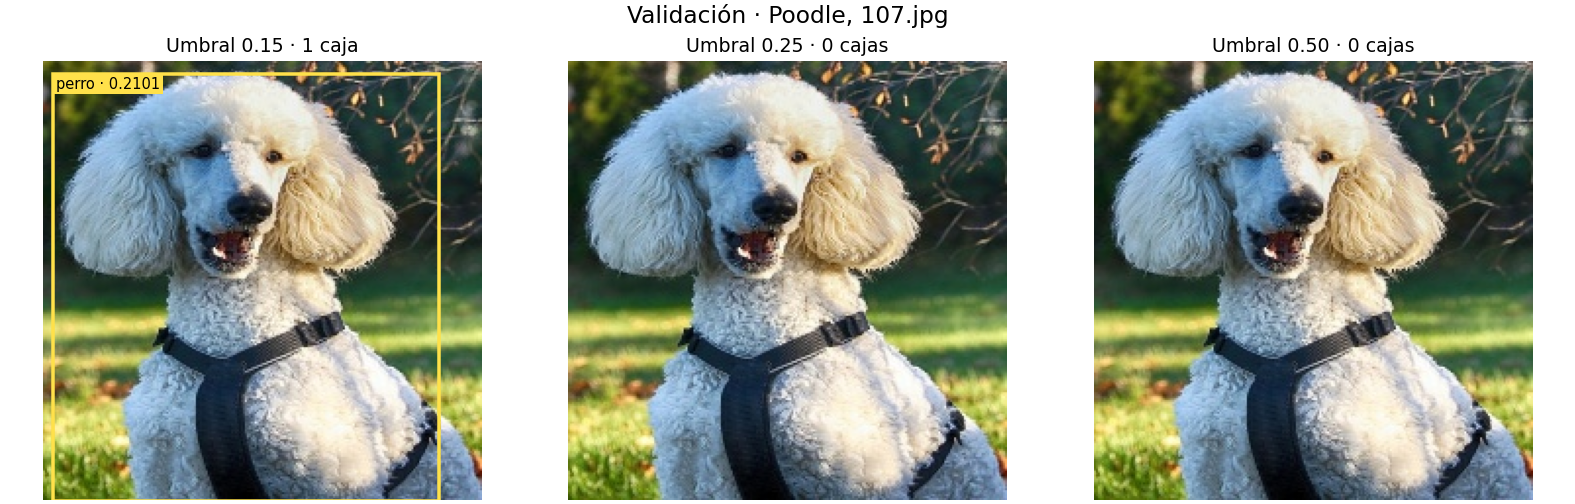

**La validación favorece `0.15`.**

In [5]:
def yolo_mostrar_cajas(evaluacion, ruta, titulo, altura):
    original = cv2.cvtColor(yolo_leer_imagen(ruta), cv2.COLOR_BGR2RGB)
    figura = Figure(figsize=(15, altura), layout="constrained")
    figura.suptitle(titulo, fontsize=16)
    resultados = evaluacion[evaluacion["Ruta"] == ruta].to_dict("records")
    for eje, resultado in zip(figura.subplots(1, 3), resultados, strict=True):
        cajas = resultado["Cajas"]
        eje.imshow(original)
        cantidad = "1 caja" if len(cajas) == 1 else f"{len(cajas)} cajas"
        eje.set_title(f"Umbral {resultado['Umbral']:.2f} · {cantidad}", fontsize=13)
        eje.set_axis_off()
        aciertos = iter(("#ffe14a", "#f259d8"))
        for (x1, y1, x2, y2), confianza, destino, revision in cajas:
            color = {
                "Falsa": "#4de0ff",
                "Duplicada": "#ffa85d",
            }.get(revision)
            if revision == "Acierto":
                color = next(aciertos, "#ffe14a")
            eje.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, lw=2.4))
            eje.annotate(
                f"{destino} · {confianza:.4f}", (x1, y1), xytext=(2, -2),
                textcoords="offset points", va="top", fontsize=10, color="black",
                bbox={"facecolor": color, "edgecolor": "none", "pad": 2},
            )
    with BytesIO() as salida:
        figura.savefig(salida, format="png", dpi=105)
        display(Image(data=salida.getvalue(), format="png", alt=titulo))

yolo_totales_validacion = yolo_validacion.groupby("Umbral")[YOLO_CONTEOS].sum()
display(yolo_totales_validacion.style.format_index("{:.2f}", axis=0))
yolo_elegido = min(
    YOLO_UMBRALES,
    key=lambda umbral: (
        yolo_totales_validacion.loc[umbral, "Omisiones"],
        yolo_totales_validacion.loc[umbral, "Cajas falsas"] + yolo_totales_validacion.loc[umbral, "Duplicadas"],
        abs(umbral - 0.25),
    ),
)
yolo_mostrar_cajas(yolo_validacion, "train/Poodle/107.jpg", "Validación · Poodle, 107.jpg", 4.8)
display(Markdown(f"**La validación favorece `{yolo_elegido:.2f}`.**"))

**Elección en validación.** `0.15` omitió 7 de los 22 perros, frente a 9 con `0.25` y 14 con `0.50`. Las cajas falsas y duplicadas fueron cero en los tres casos. Bajar de `0.25` a `0.15` recuperó el Poodle de la figura (0.2101) y el Bluetick (0.2040), cuya caja localiza la cabeza y el pecho. Todos los positivos son fotos individuales. Esta muestra aporta evidencia limitada sobre oclusiones y falsos positivos.

### Comprobación independiente

El manifiesto tiene 28 filas. Se agrupan por `path` para procesar una sola vez `escena_001.jpg`, que tiene una fila por perro. Quedan 27 imágenes únicas. Se comparan los tres umbrales con el mismo criterio visual y se informa por separado el resultado de las fotos individuales, la escena y el gato.

In [6]:
yolo_tipos = {
    "un_perro": "Fotos individuales",
    "varios_perros": "Escena con dos perros",
    "gato": "Gato",
}
yolo_rutas_independientes = {}
for yolo_fila in yolo_leer_manifiesto("independent_manifest.csv"):
    yolo_ruta = yolo_fila["path"]
    yolo_tipo = yolo_tipos[yolo_fila["scene_type"]]
    if yolo_rutas_independientes.setdefault(yolo_ruta, yolo_tipo) != yolo_tipo:
        raise ValueError(f"Tipos de escena distintos para {yolo_ruta}.")

yolo_independiente = yolo_evaluar(dict(sorted(yolo_rutas_independientes.items())))
yolo_totales_independiente = (
    yolo_independiente.groupby(["Tipo de caso", "Umbral"], sort=False)[YOLO_CONTEOS].sum()
)
display(yolo_totales_independiente.style.format_index("{:.2f}", level="Umbral", axis=0))
yolo_mostrar_revision(yolo_independiente)

Ruta,Perros visibles,0.15,0.25,0.50
independent/Beagle/beagle_001.jpg,perro,Acierto: perro (0.9361),Acierto: perro (0.9361),Acierto: perro (0.9361)
independent/Beagle/beagle_002.jpg,perro,Acierto: perro (0.9345),Acierto: perro (0.9345),Acierto: perro (0.9345)
independent/Bearded Collie/bearded_collie_001.jpg,perro,Acierto: perro (0.8126),Acierto: perro (0.8126),Acierto: perro (0.8126)
independent/Bearded Collie/bearded_collie_002.jpg,perro,Acierto: perro (0.5208),Acierto: perro (0.5208),Acierto: perro (0.5208)
independent/Border Collie/border_collie_001.jpg,perro,Acierto: perro (0.6253),Acierto: perro (0.6253),Acierto: perro (0.6253)
independent/Border Collie/border_collie_002.jpg,perro,Acierto: perro (0.9330),Acierto: perro (0.9330),Acierto: perro (0.9330)
independent/Chihuahua/chihuahua_001.jpg,perro,Acierto: perro (0.8686),Acierto: perro (0.8686),Acierto: perro (0.8686)
independent/Chihuahua/chihuahua_002.jpg,perro,Acierto: perro (0.6921),Acierto: perro (0.6921),Acierto: perro (0.6921)
independent/Chihuahua/chihuahua_003.jpg,perro,Acierto: perro (0.9193),Acierto: perro (0.9193),Acierto: perro (0.9193)
independent/Cockapoo/cockapoo_001.jpg,perro,Acierto: perro (0.6930),Acierto: perro (0.6930),Acierto: perro (0.6930)


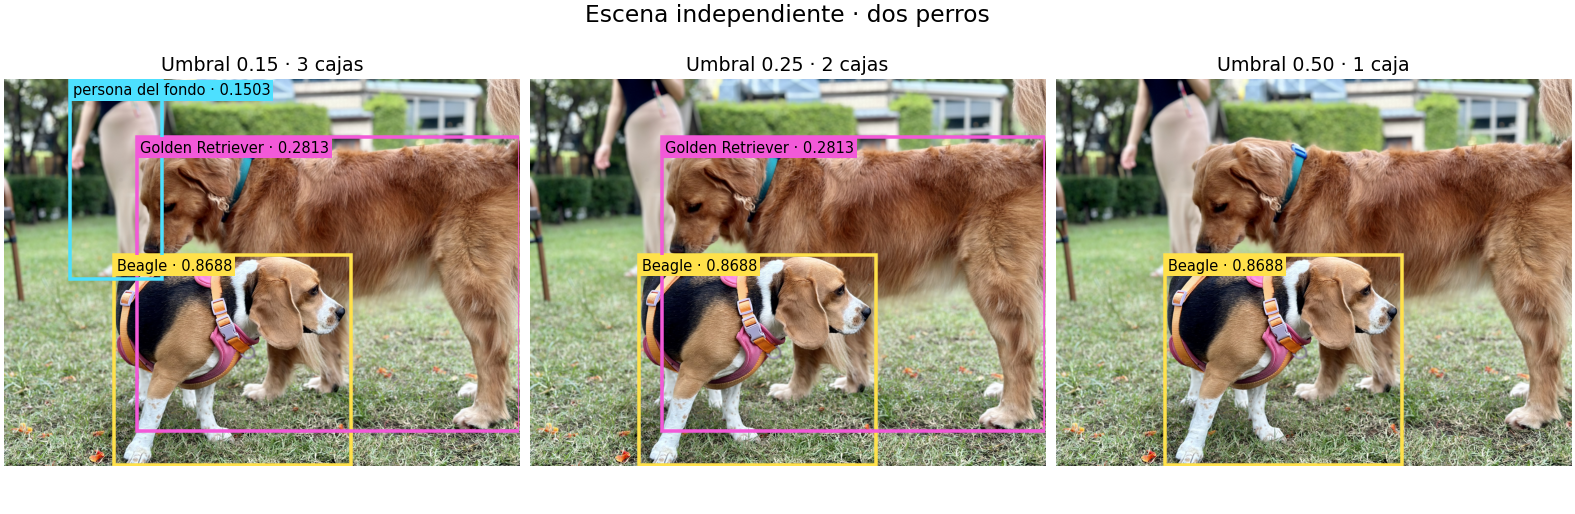

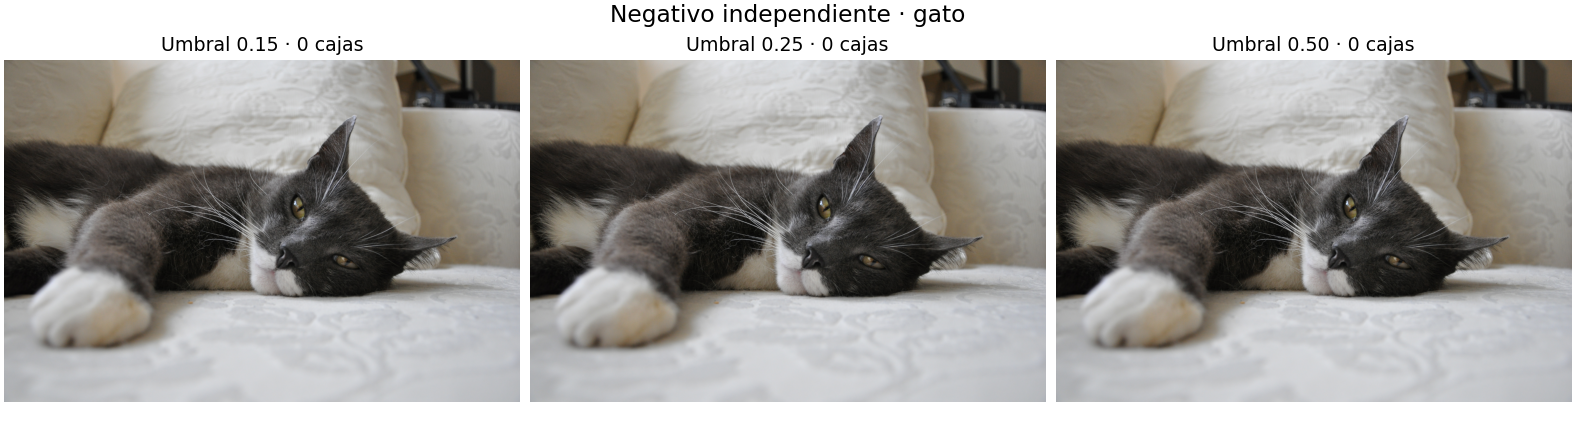

In [7]:
yolo_mostrar_cajas(
    yolo_independiente, "independent/escenas/escena_001.jpg", "Escena independiente · dos perros", 4.9
)
yolo_mostrar_cajas(
    yolo_independiente, "independent/sin_perro/gato_001.jpg", "Negativo independiente · gato", 4.1
)

El Beagle con arnés, en primer plano, tapa parte del Golden Retriever, que se inclina hacia él. Al fondo a la izquierda se ve una persona desenfocada con pantalón claro y cortada por el borde superior. Las cajas superpuestas del Beagle (0.8688) y del Golden Retriever (0.2813) localizan perros distintos. Con `0.50` queda solo la del Beagle. Al bajar de `0.25` a `0.15` aparece una caja falsa sobre la persona (0.1503) y se mantienen los mismos 26 perros detectados en el conjunto independiente. La foto del gato devuelve cero cajas con los tres umbrales.

Se conserva la elección de validación, `0.15`. Una sola escena con solapamiento permite describir este error, y la frecuencia de errores en otras escenas con personas u oclusión queda por medir.